# 06 - Imitation, Then RL

## Imports

In [1]:
import copy
import heapq
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore", category=RuntimeWarning)

# Make sure we get outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)

## What `03` Claimed

The end of `03` says that in practice the two approaches are combined: clone a policy from demonstrations so it starts out competent, then fine-tune it with RL so it can improve past the demonstrations. That paragraph hasn't been tested anywhere in this primer. This notebook runs it, and asks three questions:

1. Does the clone give RL a better starting point than random?
2. Can RL actually get past the expert?
3. What stops RL from wrecking the policy it started from?

The answers are not all as tidy as the paragraph in `03` made them sound, so the numbers below matter more than the summary.

## The Setup: An Expert That Is Wrong

This is the cliff grid from `05`. The robot starts at the bottom left, the goal is at the bottom right, and the red cells are an edge that ends the run. 15% of the time the drivetrain does something random instead of what it was told.

In `03` the expert was right about its world. Here it isn't. The expert is A\* planning as if the robot never slips, and `05` showed what that costs: it runs along the row next to the red cells and crashes about a third of the time. That is the case where imitation's ceiling matters, because a clone of this expert can match it but has no reason to do better.

The reward is the same as in `05`: -1 per step, -100 for touching the red cells.

In [2]:
H, W = 7, 12
START, GOAL = (6, 0), (6, 11)
CLIFF = {(6, c) for c in range(1, 11)}          # the edge of a field element: touching it ends the run
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]      # up, down, left, right
SLIP = 0.15                                     # chance the drivetrain does something random instead
MAX_STEPS = 60

def step_env(cell, action, blocked, rng, slip=SLIP):
    """ One real-world step. Returns (next_cell, reward, outcome) with outcome in {None, 'goal', 'crash'}. """
    if rng.random() < slip:
        action = rng.integers(4)
    r, c = cell[0] + MOVES[action][0], cell[1] + MOVES[action][1]
    nxt = (r, c) if 0 <= r < H and 0 <= c < W and (r, c) not in blocked else cell
    if nxt in CLIFF:
        return nxt, -100.0, 'crash'
    if nxt == GOAL:
        return nxt, -1.0, 'goal'
    return nxt, -1.0, None

def a_star(blocked, margin=0, start=START, goal=GOAL):
    """ A* on the planner's model: no slip. `margin` treats cells within that many cells of the cliff as blocked. """
    def keep_out(cell):
        near_cliff = any(abs(cell[0] - cr) + abs(cell[1] - cc) <= margin for cr, cc in CLIFF) if margin else False
        return cell in CLIFF or cell in blocked or (near_cliff and cell not in (start, goal))
    openset = [(0.0, 0.0, start)]
    came, best = {}, {start: 0.0}
    while openset:
        _, g, cur = heapq.heappop(openset)
        if cur == goal:
            path = [cur]
            while path[-1] in came:
                path.append(came[path[-1]])
            return path[::-1]
        for dr, dc in MOVES:
            n = (cur[0] + dr, cur[1] + dc)
            if 0 <= n[0] < H and 0 <= n[1] < W and not keep_out(n) and g + 1 < best.get(n, 1e9):
                best[n] = g + 1
                came[n] = cur
                heapq.heappush(openset, (g + 1 + abs(n[0] - goal[0]) + abs(n[1] - goal[1]), g + 1, n))
    return None

def plan_action(cell, blocked, margin=0):
    path = a_star(blocked, margin, start=cell)
    if path is None or len(path) < 2:
        return None
    return MOVES.index((path[1][0] - cell[0], path[1][1] - cell[1]))

def run_episode(choose_action, blocked, rng):
    getattr(choose_action, 'reset', lambda: None)()      # a stateful controller (like the supervisor below) starts fresh
    cell = START
    for _ in range(MAX_STEPS):
        a = choose_action(cell)
        if a is None:
            return 'stuck'
        cell, _, outcome = step_env(cell, a, blocked, rng)
        if outcome:
            return outcome
    return 'timeout'

def evaluate(choose_action, blocked, n=500, seed=0):
    rng = np.random.default_rng(seed)
    results = [run_episode(choose_action, blocked, rng) for _ in range(n)]
    return {k: results.count(k) / n for k in ['goal', 'crash', 'timeout', 'stuck']}

def evaluate_policy(probs, n=500, seed=0, slip=SLIP):
    """ Run a stochastic policy (a table of action probabilities per cell) in a world with this slip rate. Returns the goal rate. """
    rng = np.random.default_rng(seed)
    goals = 0
    for _ in range(n):
        cell = START
        for _ in range(MAX_STEPS):
            a = rng.choice(4, p=probs[:, cell[0] * W + cell[1]])
            cell, _, outcome = step_env(cell, a, set(), rng, slip)
            if outcome:
                goals += outcome == 'goal'
                break
    return goals / n

In [3]:
cmap = ListedColormap(["white", "tab:red"])

def draw(ax, paths=(), title=""):
    img = np.zeros((H, W))
    for r, c in CLIFF:
        img[r, c] = 1
    ax.imshow(img, cmap=cmap, vmin=0, vmax=1)
    for path, color, label in paths:
        ax.plot([c for r, c in path], [r for r, c in path], "-o", color=color, markersize=3, label=label)
    ax.scatter([START[1]], [START[0]], marker="s", s=90, color="tab:blue", zorder=5)
    ax.scatter([GOAL[1]], [GOAL[0]], marker="*", s=220, color="gold", edgecolor="black", zorder=5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

In [4]:
planner = lambda cell: plan_action(cell, set(), 0)
print("A* as written   :", evaluate(planner, set(), n=1000))
print("A* with margin 1:", evaluate(lambda cell: plan_action(cell, set(), 1), set(), n=1000))

A* as written   : {'goal': 0.673, 'crash': 0.327, 'timeout': 0.0, 'stuck': 0.0}


A* with margin 1: {'goal': 0.947, 'crash': 0.053, 'timeout': 0.0, 'stuck': 0.0}


So the expert reaches the goal 67% of the time. The second line is what a better expert would get. A\* with a one-cell margin around the hazard is the classical fix from `05`, and it needs no training. We won't use it as the demonstrator. The point of this notebook is what happens when nobody knows the fix.

## Step 1: Clone the Expert

The policy network is the same shape as the one in `02` and `03`: a cell goes in, four action probabilities come out. The input is a one-hot vector for the cell, so the network can give every cell its own answer. Behavior cloning is the same cross-entropy loss as before, with the expert's action as the label.

We record the expert driving the real, slippery robot 30 times. The labels are what the expert would do from each cell the robot actually ended up in, which includes cells it slipped into.

In [5]:
N_CELLS = H * W
ALL_CELLS = np.eye(N_CELLS)        # every cell as a one-hot column, so one forward pass gives the whole policy

def softmax(z):
    e = np.exp(z - z.max(axis=0, keepdims=True))
    return e / e.sum(axis=0, keepdims=True)

class PolicyNet:
    """ one-hot cell -> hidden ReLU -> 4 action logits. Same body as the policy network from 02 and 03. """
    def __init__(self, hidden=32, seed=0):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 0.3, (hidden, N_CELLS))
        self.b1 = np.zeros((hidden, 1))
        self.W2 = rng.normal(0, 0.1, (4, hidden))
        self.b2 = np.zeros((4, 1))

    def forward(self, X):
        z1 = self.W1 @ X + self.b1
        a1 = np.maximum(0, z1)
        return z1, a1, self.W2 @ a1 + self.b2

    def probs(self, X=ALL_CELLS):
        return softmax(self.forward(X)[2])

    def gradients(self, X, d_logits):
        z1, a1, _ = self.forward(X)
        d_z1 = (self.W2.T @ d_logits) * (z1 > 0)
        return [d_z1 @ X.T, d_z1.sum(axis=1, keepdims=True), d_logits @ a1.T, d_logits.sum(axis=1, keepdims=True)]

    def apply(self, grads, learning_rate):
        for param, g in zip([self.W1, self.b1, self.W2, self.b2], grads):
            param -= learning_rate * g

    def copy(self):
        return copy.deepcopy(self)

In [6]:
def expert_demos(n_episodes, rng):
    """ The flawed expert drives the real (slippery) robot. We record (cell, what the expert would do from there). """
    cells, actions = [], []
    for _ in range(n_episodes):
        cell = START
        for _ in range(MAX_STEPS):
            a = plan_action(cell, set(), 0)
            cells.append(cell)
            actions.append(a)
            cell, _, outcome = step_env(cell, a, set(), rng)
            if outcome:
                break
    return cells, np.array(actions)

def clone(cells, actions, steps=150, learning_rate=0.5, seed=0):
    """ Behavior cloning: the cross-entropy loss from 02 and 03, labels are the expert's actions. """
    net = PolicyNet(seed=seed)
    X = ALL_CELLS[:, [r * W + c for r, c in cells]]
    labels = np.eye(4)[actions].T
    for _ in range(steps):
        net.apply(net.gradients(X, (net.probs(X) - labels) / X.shape[1]), learning_rate)
    return net

demo_cells, demo_actions = expert_demos(30, np.random.default_rng(1))
cloned = clone(demo_cells, demo_actions)
print(f"{len(demo_cells)} labeled states from 30 expert drives")
print(f"expert goal rate : {evaluate(planner, set(), n=500)['goal']:.2f}")
print(f"cloned goal rate : {evaluate_policy(cloned.probs()):.2f}")

373 labeled states from 30 expert drives
expert goal rate : 0.67
cloned goal rate : 0.63


The clone reaches the goal 63% of the time against the expert's 67%. That is what `03` predicted: it copies the expert, mistakes included. Question 2 is whether RL can fix them.

## Step 2: Fine-Tune with PPO

The function below is PPO from `04` (return-to-go, a critic as the baseline, the clipped ratio, several passes over each batch), adapted to this policy. The critic here is a table of average return-to-go per cell. It has two extra terms that we'll need, both added to the gradient of the loss:

- An **entropy bonus**, which pushes the policy to keep its probabilities spread out instead of collapsing onto one action. Its coefficient is `entropy_coef`.
- A **KL penalty**, which pushes the policy to stay close to a reference policy, here the clone. Its coefficient is `kl_coef`. We'll leave it at 0 until the last section.

`ppo` returns the trained policy and, every 25 iterations, the policy's goal rate over 300 real-world runs, along with its entropy.

In [7]:
def collect(net, n_episodes, rng, slip=SLIP):
    """ Drive the robot with the current policy. `slip` is a number, or a (low, high) range to draw each episode's slip from. Returns every step as (cell index, action, prob taken, return-to-go). """
    P = net.probs()
    steps = []
    for _ in range(n_episodes):
        cell, episode = START, []
        episode_slip = rng.uniform(*slip) if isinstance(slip, tuple) else slip
        for _ in range(MAX_STEPS):
            i = cell[0] * W + cell[1]
            a = rng.choice(4, p=P[:, i])
            cell, reward, outcome = step_env(cell, a, set(), rng, episode_slip)
            episode.append((i, a, P[a, i], reward))
            if outcome:
                break
        g = 0.0
        for i, a, p_taken, reward in reversed(episode):
            g = reward + 0.99 * g
            steps.append((i, a, p_taken, g))
    return steps

def mean_entropy(net):
    """ Average entropy of the policy over the cells the robot can stand on. A uniform policy over 4 actions is ln 4 = 1.39. """
    free = [r * W + c for r in range(H) for c in range(W) if (r, c) not in CLIFF]
    P = net.probs()[:, free]
    return float((-(P * np.log(P + 1e-9)).sum(axis=0)).mean())

def kl_to(net, reference):
    """ Average KL(net || reference) over the cells the robot can stand on. """
    free = [r * W + c for r in range(H) for c in range(W) if (r, c) not in CLIFF]
    P, Q = net.probs()[:, free], reference.probs()[:, free]
    return float((P * (np.log(P + 1e-9) - np.log(Q + 1e-9))).sum(axis=0).mean())

def ppo(net, iterations=300, batch=64, learning_rate=1.0, epochs=4, clip=0.2,
        entropy_coef=0.05, kl_coef=0.0, reference=None, seed=0, eval_every=25, slip=SLIP):
    """ PPO from 04, on a one-hot-cell policy. Returns the trained copy and [(episodes so far, goal rate, entropy), ...]. """
    rng = np.random.default_rng(seed)
    net = net.copy()
    V = np.zeros(N_CELLS)                 # the critic: average return-to-go from each cell
    history, episodes = [], 0
    for it in range(iterations + 1):
        if it % eval_every == 0:
            history.append((episodes, evaluate_policy(net.probs(), n=300, seed=999), mean_entropy(net)))     # always judged in the real world
        if it == iterations:
            break
        steps = collect(net, batch, rng, slip)
        episodes += batch
        cells = np.array([s[0] for s in steps])
        actions = np.array([s[1] for s in steps])
        old_p = np.array([s[2] for s in steps])
        G = np.array([s[3] for s in steps])
        for c in np.unique(cells):
            V[c] += 0.3 * (G[cells == c].mean() - V[c])
        A = G - V[cells]
        A = A / (A.std() + 1e-8)
        X = ALL_CELLS[:, cells]
        n = len(cells)
        for _ in range(epochs):
            P = net.probs(X)
            ratio = P[actions, np.arange(n)] / old_p
            clipped_out = ((ratio > 1 + clip) & (A > 0)) | ((ratio < 1 - clip) & (A < 0))
            d_logits = -(A * ratio * ~clipped_out) * (np.eye(4)[actions].T - P)       # PPO clipped objective
            if entropy_coef:
                log_P = np.log(P + 1e-9)
                entropy = -(P * log_P).sum(axis=0, keepdims=True)
                d_logits += entropy_coef * P * (log_P + entropy)                      # bonus for staying spread out
            if kl_coef:
                log_ratio = np.log(P + 1e-9) - np.log(reference.probs()[:, cells] + 1e-9)
                kl = (P * log_ratio).sum(axis=0, keepdims=True)
                d_logits += kl_coef * P * (log_ratio - kl)                            # penalty for leaving the clone
            net.apply(net.gradients(X, d_logits / n), learning_rate)
    return net, history

## A Cloned Policy Is Too Sure of Itself to Learn

The first thing we tried was fine-tuning the clone with no entropy bonus. The cell below shows how confident the clone is, and what happens.

In [8]:
P = cloned.probs()
start_row = [P[:, START[0] * W + c].max() for c in range(W)]
print(f"average confidence of the cloned policy along the start row: {np.mean(start_row):.2f}")

_, history_plain = ppo(cloned, entropy_coef=0.0, seed=0)
print("fine-tuned with no entropy bonus (episodes, goal rate):")
print([(e, round(g, 2)) for e, g, _ in history_plain])

average confidence of the cloned policy along the start row: 0.98


fine-tuned with no entropy bonus (episodes, goal rate):
[(0, 0.65), (1600, 0.66), (3200, 0.66), (4800, 0.66), (6400, 0.66), (8000, 0.66), (9600, 0.66), (11200, 0.66), (12800, 0.66), (14400, 0.66), (16000, 0.66), (17600, 0.66), (19200, 0.66)]


The clone is 98% sure of its action in the average cell along the start row, so it tries a different action in only about 2 steps out of 100. PPO learns from the actions it samples, and it almost never samples an alternative. After 19,200 episodes the goal rate is where it started, 0.66.

That is the reason the entropy bonus is on by default (`entropy_coef=0.05`) from here on. A policy trained by cloning is confident in the places the expert went, and confidence is exactly what RL needs to give up a little of in order to find something better.

## Clone Then PPO, Against PPO From Scratch

Now the comparison. Both start with the default settings, 300 iterations of 64 episodes each, which is 19,200 episodes of real driving. The scratch policy is a freshly initialized network. We run four seeds of each.

In [9]:
SEEDS = range(4)
from_clone = [ppo(cloned, seed=s) for s in SEEDS]
from_scratch = [ppo(PolicyNet(seed=100 + s), seed=s) for s in SEEDS]

print("goal rate at the end of 19,200 episodes")
print("  fine-tuned from the clone:", [round(h[-1][1], 2) for _, h in from_clone])
print("  trained from scratch     :", [round(h[-1][1], 2) for _, h in from_scratch])

goal rate at the end of 19,200 episodes
  fine-tuned from the clone: [0.88, 0.9, 0.9, 0.88]
  trained from scratch     : [0.0, 0.0, 0.0, 0.0]


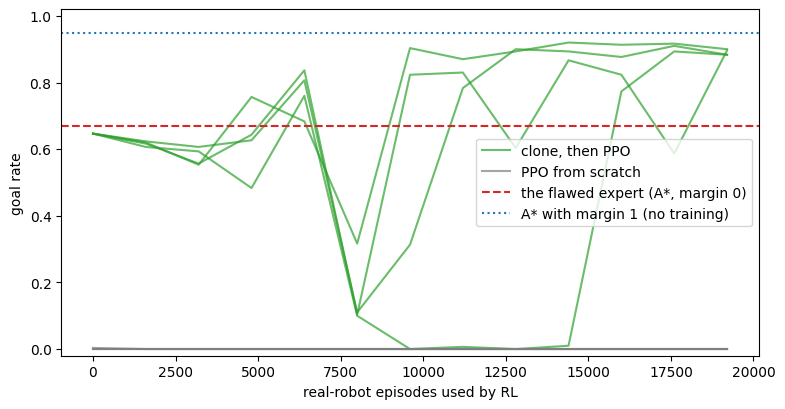

In [10]:
def curve(history):
    return [e for e, _, _ in history], [g for _, g, _ in history]

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (_, h) in enumerate(from_clone):
    ax.plot(*curve(h), color="tab:green", alpha=0.7, label="clone, then PPO" if k == 0 else None)
for k, (_, h) in enumerate(from_scratch):
    ax.plot(*curve(h), color="tab:gray", alpha=0.7, label="PPO from scratch" if k == 0 else None)
ax.axhline(0.67, color="tab:red", linestyle="--", label="the flawed expert (A*, margin 0)")
ax.axhline(0.95, color="tab:blue", linestyle=":", label="A* with margin 1 (no training)")
ax.set_xlabel("real-robot episodes used by RL")
ax.set_ylabel("goal rate")
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="center right")
plt.show()

The answer to question 2 is yes. All four fine-tuned policies end at 0.88 to 0.90, past the expert's 0.67, though still short of the 0.95 that A\* with a margin gets with no training.

The answer to question 1 is yes, and strongly. The policy trained from scratch never reaches the goal in any of the four runs. Its goal rate is 0 at the start and stays at 0. The reward gives -1 per step and nothing extra for reaching the goal, and the untrained policy reaches the goal in none of the 300 evaluation runs, so it has no successful episode to learn from. The clone starts at about 0.65 because it already knows how to get across.

Two cautions about that result. First, this is about this setup, not about RL in general: in `05`, tabular Q-learning reached the goal from scratch on this same grid, and got to about 94% within 2,000 to 5,000 episodes. Clone-then-PPO used 19,200 episodes to end at 0.88 to 0.90. This notebook is not an argument that PPO is the efficient way to solve this task. Second, 19,200 episodes is fine in a simulator and not something you would do to a real robot. We come back to that at the end.

### What RL Changed

Here is where each policy drives when nothing slips. A\* with a margin is printed alongside for comparison.

row driven along, cloned: [5]
row driven along, after PPO: [4]
row driven along, A* with margin 1: [4]


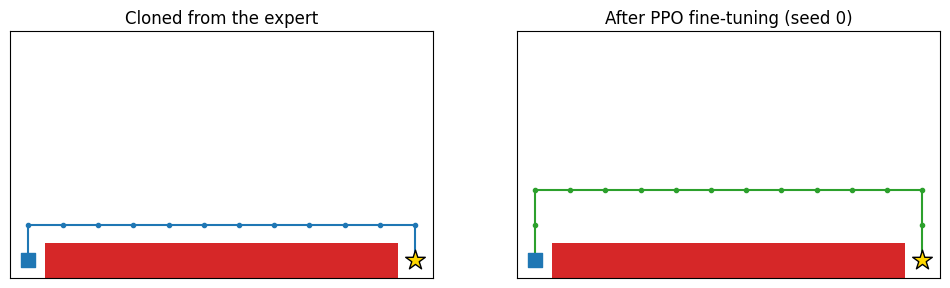

In [11]:
def greedy_path(probs, limit=40):
    """ Where the policy drives if nothing slips. """
    cell, path = START, [START]
    for _ in range(limit):
        dr, dc = MOVES[int(probs[:, cell[0] * W + cell[1]].argmax())]
        cell = (cell[0] + dr, cell[1] + dc)
        if not (0 <= cell[0] < H and 0 <= cell[1] < W):
            break
        path.append(cell)
        if cell == GOAL or cell in CLIFF:
            break
    return path

rows = lambda path: sorted({r for r, c in path[2:-2]})
print("row driven along, cloned:", rows(greedy_path(cloned.probs())))
print("row driven along, after PPO:", rows(greedy_path(from_clone[0][0].probs())))
print("row driven along, A* with margin 1:", rows(a_star(set(), 1)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
draw(axes[0], [(greedy_path(cloned.probs()), "tab:blue", "cloned")], "Cloned from the expert")
draw(axes[1], [(greedy_path(from_clone[0][0].probs()), "tab:green", "after PPO")], "After PPO fine-tuning (seed 0)")
plt.show()

The clone drives along row 5, the row right next to the red cells, copying the expert. After PPO the route moves one row away, to row 4, which is exactly where A\* with a margin of 1 drives. Nothing told the policy about margins. It found the same fix from the reward alone.

## The Part That Doesn't Match the Tidy Story

Look at the green curves above again. They don't climb smoothly. Every one of them dips partway through, and one of them sits near zero for several thousand episodes before recovering. RL fine-tuning is able to ruin the policy it started from, at least for a while.

The table below shows, for each seed, the lowest goal rate during training, and the policy's entropy at that point. The clone before PPO started had an entropy of 0.10. A policy that was equally unsure about all four actions would have 1.39.

In [12]:
print("seed | lowest goal rate | entropy at that point | entropy at the end   (max possible entropy: 1.39)")
for s, (net, h) in enumerate(from_clone):
    low = min(h[4:], key=lambda x: x[1])
    print(f"{s:<4} | {low[1]:<16.2f} | {low[2]:<21.2f} | {h[-1][2]:.2f}")
print(f"the clone before PPO started: entropy {mean_entropy(cloned):.2f}")

seed | lowest goal rate | entropy at that point | entropy at the end   (max possible entropy: 1.39)
0    | 0.00             | 0.97                  | 0.57
1    | 0.32             | 0.92                  | 0.73
2    | 0.10             | 1.09                  | 0.88
3    | 0.11             | 0.92                  | 0.67
the clone before PPO started: entropy 0.10


At the worst point of each run, the policy's entropy was between 0.92 and 1.09, much closer to a uniform policy than to the clone. So the dip is a stretch where the policy got far less sure of itself and drove accordingly. We didn't isolate what caused it. The entropy bonus is the one term in the update that pushes toward spread, and it is working against a noisy advantage signal, so it's a reasonable suspect, but we haven't shown that.

It's the problem the **KL penalty** is for. The KL divergence from the reference policy measures how far the new probabilities have moved from the clone's, averaged over cells. Adding `kl_coef` times that to the loss makes drifting away from the clone cost something. The cell below repeats the four runs with a coefficient of 0.02 and 0.05, and prints how each does.

In [13]:
from_clone_kl = {0.0: from_clone}
for coef in [0.02, 0.05]:
    from_clone_kl[coef] = [ppo(cloned, kl_coef=coef, reference=cloned, seed=s) for s in SEEDS]

print("KL coef | final goal rate per seed        | worst evaluation from iteration 100 on | drift from clone (KL)")
for coef, runs in from_clone_kl.items():
    final = [round(h[-1][1], 2) for _, h in runs]
    worst = [round(min(g for _, g, _ in h[4:]), 2) for _, h in runs]
    drift = [round(kl_to(net, cloned), 2) for net, _ in runs]
    print(f"{coef:<7} | {final} | {worst} | {drift}")

KL coef | final goal rate per seed        | worst evaluation from iteration 100 on | drift from clone (KL)
0.0     | [0.88, 0.9, 0.9, 0.88] | [0.0, 0.32, 0.1, 0.11] | [0.74, 1.41, 1.48, 1.02]
0.02    | [0.88, 0.9, 0.88, 0.86] | [0.64, 0.86, 0.65, 0.58] | [0.8, 0.47, 0.6, 0.53]
0.05    | [0.87, 0.81, 0.83, 0.8] | [0.62, 0.56, 0.62, 0.63] | [0.29, 0.19, 0.3, 0.18]


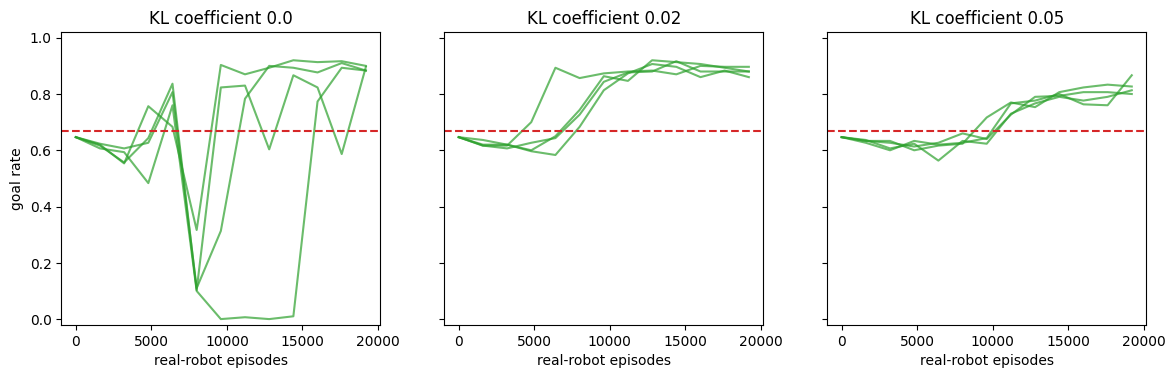

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (coef, runs) in zip(axes, from_clone_kl.items()):
    for _, h in runs:
        ax.plot(*curve(h), color="tab:green", alpha=0.7)
    ax.axhline(0.67, color="tab:red", linestyle="--")
    ax.set_title(f"KL coefficient {coef}")
    ax.set_xlabel("real-robot episodes")
axes[0].set_ylabel("goal rate")
axes[0].set_ylim(-0.02, 1.02)
plt.show()

With no penalty, all four runs end well, but the lowest goal rate each one hit along the way was between 0.00 and 0.32, and they drifted 0.74 to 1.48 in KL from the clone. With a coefficient of 0.02, none of them fell below 0.58, and they still end at 0.86 to 0.90. Their drift was 0.47 to 0.80, about half the no-penalty average (0.60 against 1.16), though one seed drifted slightly more than its no-penalty counterpart. With 0.05 the drift drops further, to 0.18 to 0.30, but the final goal rate is lower, 0.80 to 0.87. It is a dial between how far RL is allowed to improve and how far it is allowed to wander.

The dips also aren't always temporary. The cell below does the same thing with a clone that was trained longer (400 steps instead of 150), so it is even surer of itself.

In [15]:
sure_clone = clone(demo_cells, demo_actions, steps=400)
print(f"a clone trained longer: goal rate {evaluate_policy(sure_clone.probs()):.2f}, confidence along the start row {np.mean([sure_clone.probs()[:, START[0] * W + c].max() for c in range(W)]):.2f}")

for coef in [0.0, 0.02]:
    runs = [ppo(sure_clone, kl_coef=coef, reference=sure_clone, seed=s) for s in SEEDS]
    print(f"KL coefficient {coef:<4}: final goal rate per seed", [round(h[-1][1], 2) for _, h in runs])

a clone trained longer: goal rate 0.65, confidence along the start row 1.00


KL coefficient 0.0 : final goal rate per seed [0.89, 0.86, 0.9, 0.0]


KL coefficient 0.02: final goal rate per seed [0.86, 0.87, 0.87, 0.88]


This clone has about the same goal rate as before (0.65 against 0.63) and is essentially certain of its action along the start row (confidence 1.00). Without a penalty, one of the four runs ends at 0.00, having never recovered. With the penalty, all four end between 0.86 and 0.88.

This is the same KL penalty that appears in `genai_architecture_primer/05`, where the reference policy is the fine-tuned language model and RLHF is the RL step. There, the notebook notes that the penalty barely changes the outcome, because the model's best answer is already close to its starting point. Here it mattered a lot: the better policy is one row away from the clone's route, and the runs without a penalty passed through bad policies on the way.

## Fine-Tuning in a Simulator That Is Wrong

The last section said that on a real robot, the RL step would have to run in a simulator. The question is what that costs when the simulator isn't quite right. We can test it, because the slip rate is a parameter of the world.

The real robot slips 15% of the time. We fine-tune the same clone in four different simulators, then judge every resulting policy in the real world:

- slip 0.05, a simulator that is too optimistic
- slip 0.15, the correct one
- slip 0.30, a simulator that is too pessimistic
- a simulator that draws a new slip rate between 0.05 and 0.30 for every episode, which is **domain randomization** in miniature (`05` lists the paper behind it)

All four use a KL coefficient of 0.02. This cell takes a minute or two to run.

In [16]:
sim_settings = {
    "simulator slip 0.05": 0.05,
    "simulator slip 0.15 (true)": 0.15,
    "simulator slip 0.30": 0.30,
    "slip drawn from 0.05-0.30": (0.05, 0.30),
}
sim_runs = {name: [ppo(cloned, kl_coef=0.02, reference=cloned, seed=s, slip=slip) for s in SEEDS]
            for name, slip in sim_settings.items()}

sim_real = {name: [evaluate_policy(net.probs(), n=1000, seed=5) for net, _ in runs] for name, runs in sim_runs.items()}
sim_own = {name: [evaluate_policy(net.probs(), n=1000, seed=5, slip=slip) for net, _ in sim_runs[name]]
           for name, slip in sim_settings.items() if not isinstance(slip, tuple)}

print(f"{'fine-tuned in':<28} | goal rate in that simulator | goal rate in the real world (slip 0.15)")
for name in sim_settings:
    own = [round(g, 2) for g in sim_own[name]] if name in sim_own else "(no single slip rate)"
    print(f"{name:<28} | {str(own):<27} | {[round(g, 2) for g in sim_real[name]]}")

print()
print("row each policy drives along when nothing slips, per seed:")
for name, runs in sim_runs.items():
    print(f"  {name:<28} {[rows(greedy_path(net.probs())) for net, _ in runs]}")

fine-tuned in                | goal rate in that simulator | goal rate in the real world (slip 0.15)
simulator slip 0.05          | [0.84, 0.94, 0.83, 0.91]    | [0.64, 0.84, 0.68, 0.75]
simulator slip 0.15 (true)   | [0.89, 0.88, 0.9, 0.9]      | [0.89, 0.88, 0.9, 0.9]
simulator slip 0.30          | [0.8, 0.78, 0.79, 0.78]     | [0.93, 0.91, 0.91, 0.91]
slip drawn from 0.05-0.30    | (no single slip rate)       | [0.92, 0.91, 0.92, 0.92]

row each policy drives along when nothing slips, per seed:
  simulator slip 0.05          [[5], [4], [5], [5]]
  simulator slip 0.15 (true)   [[4], [4], [4], [4]]
  simulator slip 0.30          [[4], [4], [3, 4], [4]]
  slip drawn from 0.05-0.30    [[4], [4], [4], [4]]


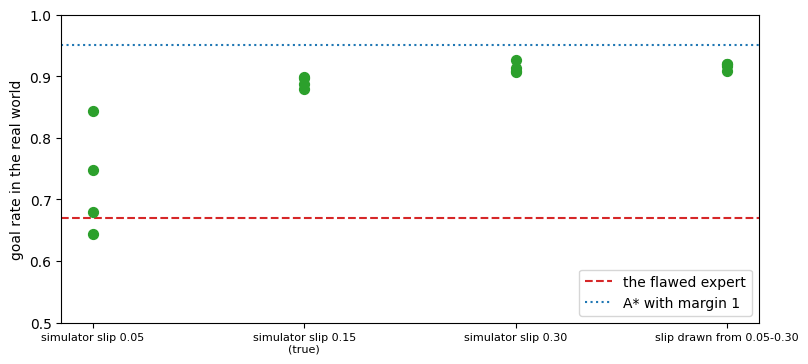

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, (name, goals) in enumerate(sim_real.items()):
    ax.scatter([k] * len(goals), goals, color="tab:green", s=50, zorder=3)
ax.axhline(0.67, color="tab:red", linestyle="--", label="the flawed expert")
ax.axhline(0.95, color="tab:blue", linestyle=":", label="A* with margin 1")
ax.set_xticks(range(len(sim_real)))
ax.set_xticklabels([n.replace(" (true)", "\n(true)") for n in sim_real], fontsize=8)
ax.set_ylabel("goal rate in the real world")
ax.set_ylim(0.5, 1.0)
ax.legend(loc="lower right")
plt.show()

The optimistic simulator is the one that hurts. The four policies fine-tuned in it look fine in their own world, with goal rates of 0.83 to 0.94, and then score 0.64 to 0.84 on the real robot. Two of the four, at 0.64 and 0.68, are no better than the expert they started from (0.67). The routes fit this: three of the four still drive along row 5 next to the red cells, the clone's route. We didn't test why, but it makes sense that when slipping is rare, hugging the cliff costs little, so there is less for RL to gain by moving away from it.

The correct simulator gives 0.88 to 0.90 on the real robot, as before. It is the baseline here, since its world is the real world.

The pessimistic simulator was wrong in the other direction, and it didn't hurt. The policies score only 0.78 to 0.80 in their own, harsher world, and 0.91 to 0.93 on the real robot, slightly above the correct simulator's 0.88 to 0.90. The gap is small, though all four seeds sit above all four seeds of the correct run. Their routes are almost the same as the correct simulator's (row 4 for three seeds, a mix of rows 3 and 4 for the fourth), so this run can't say what produced the extra 0.02 or 0.03.

The randomized simulator scores 0.91 to 0.92 on the real robot, in line with the pessimistic one, and every seed drives along row 4, even though some of its episodes were drawn from the easy end of the range.

Two things to take from this, both on this one grid. A policy's score in the simulator it was trained in can overstate how it will do on the robot, as the optimistic simulator's policies show (0.83 to 0.94 at home, 0.64 to 0.84 real). And a wrong simulator isn't equally costly both ways. Too optimistic hurt, too pessimistic didn't, and drawing the parameter from a range that contained the real value did about as well as getting it exactly right.

## What This Does and Doesn't Show

What it shows, on this grid with these settings:

- A clone can't beat its expert (0.63 against 0.67), and this clone copied the expert's mistake.
- PPO fine-tuning from the clone got past the expert in all four seeds (0.88 to 0.90) and found the same route a classical fix would.
- PPO from a random start never got off zero in 19,200 episodes.
- A clone is too confident for RL to change without something keeping it exploring (the entropy bonus), and an RL loop that explores can undo the clone without something holding it back (the KL penalty).
- A policy fine-tuned in a simulator that is too optimistic about slip can score well there and poorly on the real robot (0.83 to 0.94 at home, 0.64 to 0.84 real).

What it doesn't show:

- That RL from scratch can't solve this. `05`'s Q-learning did.
- That PPO is a cost-effective choice here. A\* with a margin gets 0.95 with no training at all.
- That these settings are right in general. The entropy and KL coefficients were chosen by trying values on this one grid. When we tried an entropy coefficient of 0.1 while building this notebook, the policy lost its way entirely and the goal rate fell to roughly zero. The window between "too confident to learn" and "too random to work" is not wide.
- That a wrong simulator is always costly. The pessimistic one did slightly better on the real robot than the correct one.
- That a real simulator's errors look like this. Ours is the same grid with one number changed, and a real simulator can be wrong in many more ways at once.
- That four seeds on a 7 by 12 grid says much about a real robot.

The most honest summary is that imitation then RL works, and that each of the two steps leaves a failure that the other step needs a guard against.

## Back to the Robot

For our own robot, the plan in `03` was to record the drive team's best matches and clone a policy from them. This notebook adds the next step and a warning about it.

The RL step used 19,200 episodes. You can't run that many on a real robot, so the fine-tuning would happen in a simulator. That brings back the sim-to-real gap from `05`, and the section above measured it for one parameter: a simulator that was too optimistic about slip produced policies that scored well at home and poorly on the real drivetrain. On this grid, two choices avoided the problem, a simulator that was too pessimistic and one that drew the slip rate from a range containing the real value. Neither is proven in general, and measuring the real slip rate is better than either. `perception_primer/10-full-autonomy-stack.ipynb` has a simulator for the whole stack and says plainly that a simulator alone can't validate a real team's stack, which applies here too.

The other thing the notebook suggests is where to look when it goes wrong. If the fine-tuned policy is worse than the clone, check whether the entropy bonus has turned it into a random driver. If it has left the clone behind and gotten worse, check how far it has drifted. Both are numbers you can log during training, like the two columns in the table above.

## Try It Yourself

1. Set `entropy_coef=0.1` and fine-tune the clone. Does the goal rate collapse the way it did while this notebook was being built? Then try 0.03. How wide is the window where fine-tuning works?
2. Use a better expert. Change `expert_demos` to plan with margin 1 instead of 0, clone it, and evaluate. How much is left for RL to add?
3. Add a bonus for reaching the goal (for example, +20 in `step_env`) and train from a random start with no clone. Does the scratch policy start learning, and how many episodes does it take?
4. Narrow the randomized simulator to `(0.05, 0.10)`, a range that doesn't contain the real slip rate of 0.15. Does randomization still protect the policy?

In [18]:
# TODO: 1. fine-tune the clone with entropy_coef=0.1, then 0.03

# TODO: 2. clone an expert that plans with margin 1, and evaluate it before any RL

# TODO: 3. add a goal bonus to step_env and train a policy from scratch

# TODO: 4. fine-tune with slip=(0.05, 0.10) and evaluate at the real slip of 0.15

## Resources

- [Ross, Gordon & Bagnell (2011), "A Reduction of Imitation Learning and Structured Prediction to No-Regret Online Learning"](https://arxiv.org/abs/1011.0686) - the DAgger paper from `03`, which is the other way of making a clone better, using more expert labels instead of reward (paper).
- Silver, D. et al. (2016). "Mastering the Game of Go with Deep Neural Networks and Tree Search." *Nature*, 529. A policy network first trained by supervised learning on expert games, then improved with RL, the clone-then-fine-tune recipe at scale (paper).
- [Hester et al. (2018), "Deep Q-learning from Demonstrations"](https://arxiv.org/abs/1704.03732) - a way of mixing demonstrations into a value-based RL agent, rather than starting a policy-gradient agent from a clone (paper).
- `genai_architecture_primer/05-post-training-instruction-tuning-and-rlhf.ipynb` - the same clone-then-RL shape for a language model, with the KL penalty against a frozen reference.
- `05-rl-in-the-autonomy-stack.ipynb` - the cliff grid this notebook reuses, and the Q-learning and classical-planner results it compares against.